# ML FINAL — Instruction Notebook (67010593)
**How to use in the exam**
1. Copy the teacher's csv into the same folder as this notebook.
2. Go to **Part B — CONFIG**. Change only the lines marked `# <<< CHANGE`.
3. `Kernel → Restart & Run All`. Every graph + ranking table is produced automatically.
4. If the data is dirty, use the recipes in **Part A** first, then put the cleaning lines in `clean()` inside the CONFIG cell.
5. If anything explodes and time is short → **EMERGENCY** cells at the end (your original Gradient Boosting code).

| Part | What | Points |
|---|---|---|
| Q1 Regression **from scratch** (numpy only) | train → predict → compare R² | 10 |
| Q2 Classification + Regression (**sklearn OK**) | train classifiers → predict (accuracy / F1) → use predicted class to predict the regression target | 15 |
| Each part | train finished 4 · predict correct 2 · rank vs friends 4 | |

**Ranking vs friends = higher test score wins.** The "Best" model in each part is chosen automatically by
**5-fold cross-validation on TRAIN** (not by peeking at test), so it is the most reliable pick on an unseen dataset.

Section map: A. Data cookbook · B. CONFIG + prepare · Q1 (4 graphs + R² ranking) · Q2 (classifier bar chart + class ranking, 4 regression graphs + regression ranking) · Predict a given row · EMERGENCY · Checklist

---
# Part A — Data cookbook (every case)
Run these on a **copy** (`d = df.copy()`) to look, then put the line you choose into `clean()` in Part B.

### Decision table — missing values
| Situation | Do this | Code |
|---|---|---|
| Few rows missing (< ~5 %) | drop those rows | `d = d.dropna(subset=["Age"])` |
| Column mostly empty (> ~40–50 %, e.g. Cabin) | drop the column | `d = d.drop(columns=["Cabin"])` |
| Number, roughly symmetric | fill **mean** | `d["Age"] = d["Age"].fillna(d["Age"].mean())` |
| Number, skewed / outliers (money, Fare, income) | fill **median** (safer) | `d["Fare"] = d["Fare"].fillna(d["Fare"].median())` |
| "Missing means none" (count, amount, bonus) | fill **0** | `d["SibSp"] = d["SibSp"].fillna(0)` |
| Text / category | fill **mode** (most common) or `"Unknown"` | `d["Embarked"] = d["Embarked"].fillna(d["Embarked"].mode()[0])` |
| Depends on group (Age by Pclass/Sex) | fill **group median** | `d["Age"] = d["Age"].fillna(d.groupby(["Pclass","Sex"])["Age"].transform("median"))` |
| Time series / ordered rows | forward fill | `d["x"] = d["x"].ffill()` |
| Missingness itself is information | add a flag then fill | `d["Age_missing"] = d["Age"].isna().astype(int)` |
| Target (y) missing | **always drop the row** (never fill y) | `d = d.dropna(subset=[TARGET])` |

**Rule of thumb for score:** filling (median) keeps more rows → usually better than `dropna()` on everything.
**pandas 3 trap:** `df["Age"].fillna(0, inplace=True)` does **nothing** now. Always write `df["Age"] = df["Age"].fillna(0)`.

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

df = pd.read_csv("../titanic.csv")      # A-cookbook demo file (Part B loads the real one)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# 1) LOOK at the data: types, missing, unique values
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(1),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
print("duplicated rows:", df.duplicated().sum())
info

duplicated rows: 0


,dtype,missing,missing_%,unique,example
PassengerId,int64,0,0.0,891,1
Survived,int64,0,0.0,2,0
Pclass,int64,0,0.0,3,3
Name,str,0,0.0,891,"Braund, Mr. Owen Harris"
Sex,str,0,0.0,2,male
Age,float64,177,19.9,88,22.0
SibSp,int64,0,0.0,7,1
Parch,int64,0,0.0,7,0
Ticket,str,0,0.0,681,A/5 21171
Fare,float64,0,0.0,248,7.25


In [3]:
df.describe().T          # min / max / mean -> spot weird values (0 age, negative price, 9999 codes)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [4]:
# 2) MISSING VALUES — every strategy on a copy, compare how many rows/NaN remain
d = df.copy()
print("dropna all rows        :", d.dropna().shape)                       # kills rows with ANY NaN (Cabin -> very few rows!)
print("dropna only some cols  :", d.dropna(subset=["Age", "Embarked"]).shape)
print("drop column Cabin      :", d.drop(columns=["Cabin"]).shape)
print("drop cols > 40% missing:", d.loc[:, d.isnull().mean() < 0.4].shape)

d["Age_zero"]   = d["Age"].fillna(0)
d["Age_mean"]   = d["Age"].fillna(d["Age"].mean())
d["Age_median"] = d["Age"].fillna(d["Age"].median())
d["Age_group"]  = d["Age"].fillna(d.groupby(["Pclass", "Sex"])["Age"].transform("median"))
d["Embarked"]   = d["Embarked"].fillna(d["Embarked"].mode()[0])
d["Cabin"]      = d["Cabin"].fillna("Unknown")
print(d[["Age", "Age_zero", "Age_mean", "Age_median", "Age_group"]].head(6))

# fill ALL number columns at once / ALL text columns at once
num_cols = d.select_dtypes(include="number").columns
txt_cols = d.columns.difference(num_cols)
d[num_cols] = d[num_cols].fillna(d[num_cols].median())
for c in txt_cols:
    d[c] = d[c].fillna(d[c].mode()[0])
print("NaN left:", d.isnull().sum().sum())

dropna all rows        : (183, 12)
dropna only some cols  : (712, 12)
drop column Cabin      : (891, 11)
drop cols > 40% missing: (891, 11)
    Age  Age_zero   Age_mean  Age_median  Age_group
0  22.0      22.0  22.000000        22.0       22.0
1  38.0      38.0  38.000000        38.0       38.0
2  26.0      26.0  26.000000        26.0       26.0
3  35.0      35.0  35.000000        35.0       35.0
4  35.0      35.0  35.000000        35.0       35.0
5   NaN       0.0  29.699118        28.0       25.0
NaN left: 0


In [5]:
# 3) TEXT -> NUMBER (models only eat numbers)
d = df.copy()
d["Sex_num"] = d["Sex"].map({"male": 1, "female": 0})          # 2 categories -> 0/1
d["Emb_code"] = d["Embarked"].astype("category").cat.codes      # label codes (NaN -> -1); OK for trees
dummies = pd.get_dummies(d["Embarked"], prefix="Emb", dtype=float)  # one-hot: best for linear/KNN
d = pd.concat([d, dummies], axis=1)
print(d[["Sex", "Sex_num", "Embarked", "Emb_code"] + list(dummies.columns)].head())

# whole table at once (drops the text column, adds 0/1 columns):
# X = pd.get_dummies(d[FEATURES], drop_first=True, dtype=float)

# ordered categories -> keep the order yourself
# d["size"] = d["size"].map({"S": 0, "M": 1, "L": 2, "XL": 3})

      Sex  Sex_num Embarked  Emb_code  Emb_C  Emb_Q  Emb_S
0    male        1        S         2    0.0    0.0    1.0
1  female        0        C         0    1.0    0.0    0.0
2  female        0        S         2    0.0    0.0    1.0
3  female        0        S         2    0.0    0.0    1.0
4    male        1        S         2    0.0    0.0    1.0


In [6]:
# 4) DIRTY NUMBERS stored as text  ("1,234", "$50", "12 km", "?", "N/A")
s = pd.Series(["1,234", "$50", "12 km", "?", "N/A", "7.5"])
clean = pd.to_numeric(s.str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")   # bad -> NaN, then fill
print(clean.tolist())
# special codes meaning missing: df = df.replace({"?": np.nan, -999: np.nan, "": np.nan})
# strip spaces / unify case:      df["col"] = df["col"].str.strip().str.lower()

[1234.0, 50.0, 12.0, nan, nan, 7.5]


In [7]:
# 5) DATES -> numbers
dates = pd.Series(["01/01/2018 00:15", "15/03/2018 13:45"])
t = pd.to_datetime(dates, dayfirst=True)
print(pd.DataFrame({"year": t.dt.year, "month": t.dt.month, "day": t.dt.day,
                    "dayofweek": t.dt.dayofweek, "hour": t.dt.hour,
                    "weekend": (t.dt.dayofweek >= 5).astype(int)}))
# then DROP the original date-string column

   year  month  day  dayofweek  hour  weekend
0  2018      1    1          0     0        0
1  2018      3   15          3    13        0


In [8]:
# 6) DROP useless columns, DUPLICATES, OUTLIERS, NEW FEATURES
d = df.copy()
d = d.drop(columns=["PassengerId", "Name", "Ticket"])   # ids / free text / almost-unique columns (nunique ~ rows)
d = d.drop_duplicates()
# outliers: clip a FEATURE to the 1%..99% range (do NOT clip the target you must predict)
lo, hi = d["Age"].quantile([0.01, 0.99])
d["Age"] = d["Age"].clip(lo, hi)
# remove impossible rows: d = d[d["Age"] >= 0]
# new features (often a free score boost)
d["FamilySize"] = df["SibSp"] + df["Parch"] + 1
d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
d["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]          # Mr / Mrs / Miss / Master ...
print(d[["FamilySize", "IsAlone", "Title"]].head())

   FamilySize  IsAlone Title
0           2        0    Mr
1           2        0   Mrs
2           1        1  Miss
3           2        0   Mrs
4           1        1    Mr


In [9]:
# 7) WHICH FEATURES MATTER? correlation with the target (numbers only)
d = df.copy()
d["Sex"] = (d["Sex"] == "male").astype(int)
print(d.select_dtypes("number").corr()["Fare"].drop("Fare").sort_values(key=abs, ascending=False).round(3))
print()
print(df["Survived"].value_counts(normalize=True).round(3))   # class balance: imbalanced -> trust F1 more than accuracy

Pclass        -0.549
Survived       0.257
Parch          0.216
Sex           -0.182
SibSp          0.160
Age            0.096
PassengerId    0.013
Name: Fare, dtype: float64

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


### Common errors → fix
| Error | Fix |
|---|---|
| `could not convert string to float` | a text column is still in X → `map` / `get_dummies` / drop it |
| `Input X contains NaN` | fill or drop missing values first (Part A §2) |
| `LinAlgError: Singular matrix` | use `np.linalg.pinv` or Ridge `lam > 0` (toolbox already does) |
| R² negative / nan in GD | standardise X, lower learning rate |
| `shapes not aligned` | 1 feature must be 2-D: `X[:, [j]]`, not `X[:, j]` |
| `Target is multiclass` in f1 | `f1_score(..., average="macro")` (CONFIG does it automatically) |
| `KeyError: 'col'` | check spelling: `print(df.columns.tolist())`, strip spaces: `df.columns = df.columns.str.strip()` |
| file not found | `pd.read_csv(r"C:\full\path\file.csv")`, or `sep=";"` if everything lands in 1 column |
| Thai text garbled | `pd.read_csv(path, encoding="utf-8-sig")` or `encoding="cp874"` |
| `SettingWithCopyWarning` | `d = d.copy()` after filtering |

---
# Part B — CONFIG + prepare data  (the ONLY cell you must edit)

In [10]:
# ======================= CONFIG — change the lines marked <<< CHANGE =======================
CSV        = "../titanic.csv"      # <<< CHANGE  file name (add sep=";" below if needed)
TEST_CSV   = None               # <<< CHANGE  if teacher gives a separate test file, e.g. "test.csv"
REG_TARGET = "Fare"             # <<< CHANGE  number to predict (Q1 and Q2 regression)
CLS_TARGET = "Survived"         # <<< CHANGE  class to predict (Q2). None -> build from REG_TARGET with THRESHOLD
THRESHOLD  = None               #             e.g. 6 -> class = REG_TARGET >= 6 (only when CLS_TARGET is None)
FEATURES   = None               # <<< CHANGE  None = use every usable column, or a list e.g. ["Age", "Pclass", "SibSp"]
DROP_COLS  = ["PassengerId", "Name", "Ticket"]   # <<< CHANGE ids / free text
FILL       = "median"           # "median" | "mean" | "zero" | "drop"   (numbers; text always gets mode)
MAX_MISSING = 0.4               # drop a column if more than 40 % is missing (e.g. Cabin)
TEST_SIZE  = 0.2
SEED       = 42
QUICK      = False              # True = fewer CV folds / trees (use if the dataset is big and time is short)

def clean(df):
    # put extra cleaning lines from Part A here, e.g.
    # df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    return df
# ===========================================================================================

In [11]:
raw = pd.read_csv(CSV)
raw.columns = raw.columns.str.strip()
n_given_train = len(raw)
if TEST_CSV:                                   # teacher's own test file -> stack, prepare together, split back
    raw = pd.concat([raw, pd.read_csv(TEST_CSV)], ignore_index=True)

def prepare(raw):
    df = clean(raw.copy())
    df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
    df = df.dropna(subset=[REG_TARGET] + ([CLS_TARGET] if CLS_TARGET else []))      # never fill a target
    if CLS_TARGET is None:
        df["_class"] = (df[REG_TARGET] >= THRESHOLD).astype(int)
    cls_col = CLS_TARGET or "_class"
    targets = [REG_TARGET, cls_col]
    feats = FEATURES or [c for c in df.columns if c not in targets]
    X = df[feats].copy()
    X = X.loc[:, X.isnull().mean() <= MAX_MISSING]                          # drop mostly-empty columns
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    txt = [c for c in X.columns if c not in num]
    txt = [c for c in txt if X[c].nunique() <= 20]                          # too many categories -> drop (free text)
    if FILL == "drop":
        keep = X[num + txt].notna().all(axis=1)
        X, df = X[keep], df[keep]
    else:
        fill = {"median": X[num].median(), "mean": X[num].mean(), "zero": 0}[FILL]
        X[num] = X[num].fillna(fill)
    for c in txt:
        X[c] = X[c].fillna(X[c].mode()[0]).astype(str)
    X = pd.get_dummies(X[num + txt], columns=txt, drop_first=True, dtype=float)
    return X.astype(float), df[REG_TARGET].to_numpy(float), np.array(df[cls_col].tolist()), df.index

X_df, y_reg, y_cls, kept_idx = prepare(raw)
feature_names = X_df.columns.tolist()
X = X_df.to_numpy()

# one split shared by Q1 and Q2 (numpy only -> allowed in the from-scratch part)
if TEST_CSV:
    is_test = kept_idx >= n_given_train
    tr_idx, te_idx = np.where(~is_test)[0], np.where(is_test)[0]
else:
    perm = np.random.default_rng(SEED).permutation(len(X))
    n_te = int(round(TEST_SIZE * len(X)))
    te_idx, tr_idx = perm[:n_te], perm[n_te:]
X_train, X_test = X[tr_idx], X[te_idx]
yr_train, yr_test = y_reg[tr_idx], y_reg[te_idx]
yc_train, yc_test = y_cls[tr_idx], y_cls[te_idx]
print("features:", feature_names)
print("train", X_train.shape, "| test", X_test.shape, "| classes:", dict(zip(*np.unique(y_cls, return_counts=True))))

features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Sex_male', 'Embarked_Q', 'Embarked_S']
train (713, 7) | test (178, 7) | classes: {np.int64(0): np.int64(549), np.int64(1): np.int64(342)}


---
# Q1 — Regression FROM SCRATCH (numpy only)  · 10 p
Toolbox: R², standardise, OLS / Ridge (normal equation), Polynomial deg 2, KNN, regression tree,
Gradient Boosting (trees), Random Forest, your stump Boost, k-fold CV. All numpy.

In [12]:
# ===================== FROM-SCRATCH TOOLBOX (numpy only) =====================
def r2(y, p):
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def rmse(y, p):
    return np.sqrt(((y - p) ** 2).mean())

class Scaler:                                  # z = (x - mean_train) / std_train
    def fit(self, X):
        self.mu, self.sd = X.mean(0), X.std(0)
        self.sd[self.sd == 0] = 1
        return self
    def transform(self, X):
        return (X - self.mu) / self.sd

def poly2(X):                                  # x1..xn, then every xi*xj (squares + pairs)
    cols = [X]
    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            cols.append((X[:, i] * X[:, j])[:, None])
    return np.hstack(cols)

class LinearReg:                               # OLS (lam=0) or Ridge (lam>0); bias not penalised
    def __init__(self, lam=0.0, poly=False):
        self.lam, self.poly = lam, poly
    def _f(self, X):
        Z = self.sc.transform(X)
        if self.poly:
            Z = poly2(Z)
        return np.c_[np.ones(len(Z)), Z]
    def fit(self, X, y):
        self.sc = Scaler().fit(X)
        A = self._f(X)
        I = np.eye(A.shape[1]); I[0, 0] = 0
        self.w = np.linalg.pinv(A.T @ A + self.lam * I) @ A.T @ y
        return self
    def predict(self, X):
        return self._f(X) @ self.w

class LinearGD:                                # same line, learned with gradient descent (if teacher asks for GD)
    def __init__(self, lr=0.05, epochs=2000):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        self.sc = Scaler().fit(X)
        A = np.c_[np.ones(len(X)), self.sc.transform(X)]
        self.w = np.zeros(A.shape[1])
        for _ in range(self.epochs):
            self.w -= self.lr * (2 / len(y)) * A.T @ (A @ self.w - y)
        return self
    def predict(self, X):
        return np.c_[np.ones(len(X)), self.sc.transform(X)] @ self.w

class KNNReg:                                  # distance-weighted average of k nearest rows
    def __init__(self, k=7):
        self.k = k
    def fit(self, X, y):
        self.sc = Scaler().fit(X); self.A = self.sc.transform(X); self.y = y
        return self
    def predict(self, X):
        B = self.sc.transform(X); out = []
        for s in range(0, len(B), 500):            # chunks -> no memory blow-up on big data
            d = ((B[s:s+500, None, :] - self.A[None]) ** 2).sum(-1)
            nn = np.argsort(d, 1)[:, :self.k]
            w = 1 / (np.sqrt(np.take_along_axis(d, nn, 1)) + 1e-6)
            out.append((self.y[nn] * w).sum(1) / w.sum(1))
        return np.concatenate(out)

def tree_fit(X, r, depth, min_leaf):           # regression tree, best split by sorted cumulative sums
    if depth == 0 or len(r) < 2 * min_leaf:
        return r.mean()
    n, best = len(r), (((r - r.mean()) ** 2).sum(), None, None)
    nl = np.arange(1, n); nr = n - nl
    for j in range(X.shape[1]):
        o = np.argsort(X[:, j], kind="stable"); xs, rs = X[o, j], r[o]
        cs, cs2 = np.cumsum(rs), np.cumsum(rs ** 2)
        sse = (cs2[:-1] - cs[:-1] ** 2 / nl) + (cs2[-1] - cs2[:-1] - (cs[-1] - cs[:-1]) ** 2 / nr)
        ok = (xs[:-1] != xs[1:]) & (nl >= min_leaf) & (nr >= min_leaf)
        if ok.any():
            i = np.where(ok, sse, np.inf).argmin()
            if sse[i] < best[0]:
                best = (sse[i], j, (xs[i] + xs[i + 1]) / 2)
    if best[1] is None:
        return r.mean()
    _, j, t = best
    m = X[:, j] <= t
    return (j, t, tree_fit(X[m], r[m], depth - 1, min_leaf), tree_fit(X[~m], r[~m], depth - 1, min_leaf))

def tree_predict(node, X):
    if not isinstance(node, tuple):
        return np.full(len(X), node)
    j, t, L, R = node
    m = X[:, j] <= t
    out = np.empty(len(X))
    out[m], out[~m] = tree_predict(L, X[m]), tree_predict(R, X[~m])
    return out

class GBScratch:                               # gradient boosting = many small trees fixing the error left
    def __init__(self, n=300, lr=0.05, depth=3, min_leaf=5, sub=0.8, log_y=False, seed=42):
        self.n, self.lr, self.depth, self.min_leaf, self.sub, self.log_y, self.seed = n, lr, depth, min_leaf, sub, log_y, seed
    def fit(self, X, y):
        y = np.log1p(y) if self.log_y else y
        rng = np.random.default_rng(self.seed)
        self.base, self.trees = y.mean(), []
        p = np.full(len(y), self.base)
        for _ in range(self.n):
            idx = rng.choice(len(y), int(self.sub * len(y)), replace=False)
            t = tree_fit(X[idx], (y - p)[idx], self.depth, self.min_leaf)
            p += self.lr * tree_predict(t, X)
            self.trees.append(t)
        return self
    def predict(self, X):
        p = self.base + self.lr * sum(tree_predict(t, X) for t in self.trees)
        return np.expm1(p) if self.log_y else p

class RFScratch:                               # random forest = average of trees on bootstrap samples
    def __init__(self, n=100, depth=8, min_leaf=3, seed=42):
        self.n, self.depth, self.min_leaf, self.seed = n, depth, min_leaf, seed
    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.trees = []
        for _ in range(self.n):
            idx = rng.integers(0, len(y), len(y))
            self.trees.append(tree_fit(X[idx], y[idx], self.depth, self.min_leaf))
        return self
    def predict(self, X):
        return np.mean([tree_predict(t, X) for t in self.trees], axis=0)

class StumpBoost:                              # YOUR original boost() (depth-1 trees, 50 rounds) as a class
    def __init__(self, n=50, lr=0.1):
        self.n, self.lr = n, lr
    def fit(self, X, y):
        self.base, self.trees = y.mean(), []
        p = np.full(len(y), self.base)
        for _ in range(self.n):
            t = tree_fit(X, y - p, 1, 1)
            p += self.lr * tree_predict(t, X)
            self.trees.append(t)
        return self
    def predict(self, X):
        return self.base + self.lr * sum(tree_predict(t, X) for t in self.trees)

class Blend:                                   # average of several models -> errors cancel
    def __init__(self, *models):
        self.models = models
    def fit(self, X, y):
        for m in self.models:
            m.fit(X, y)
        return self
    def predict(self, X):
        return np.mean([m.predict(X) for m in self.models], axis=0)

def cv_r2(make_model, X, y, k=5, seed=42):     # k-fold cross-validation R² on TRAIN only
    folds = np.array_split(np.random.default_rng(seed).permutation(len(X)), k)
    scores = []
    for i in range(k):
        va = folds[i]; tr = np.concatenate([folds[j] for j in range(k) if j != i])
        scores.append(r2(y[va], make_model().fit(X[tr], y[tr]).predict(X[va])))
    return float(np.mean(scores))
print("toolbox ready")

toolbox ready


In [13]:
# ===================== Q1 TRAIN =====================
K = 3 if QUICK else 5
N_TREES = 150 if QUICK else 300
pos_y = bool((yr_train >= 0).all())          # log-target trick only works for y >= 0 (prices, counts)

# Model 1: simple linear = the ONE feature most correlated with y
corr = [abs(np.corrcoef(X_train[:, j], yr_train)[0, 1]) if X_train[:, j].std() > 0 else 0 for j in range(X.shape[1])]
best_j = int(np.nanargmax(corr))
print("simple linear uses:", feature_names[best_j], "| |corr| =", round(corr[best_j], 3))

# Model 3: polynomial degree 2 + Ridge, lambda chosen by CV
lam_scores = {lam: cv_r2(lambda: LinearReg(lam, poly=True), X_train, yr_train, K) for lam in [0.1, 1, 10, 100]}
best_lam = max(lam_scores, key=lam_scores.get)
print("poly ridge lambda CV:", {k: round(v, 3) for k, v in lam_scores.items()}, "-> lambda =", best_lam)

# Model 4: BEST = pick by CV among strong candidates
candidates = {
    "Poly2 Ridge":              lambda: LinearReg(best_lam, poly=True),
    "KNN (k=7)":                lambda: KNNReg(7),
    "KNN (k=15)":               lambda: KNNReg(15),
    "GradBoost scratch":        lambda: GBScratch(n=N_TREES),
    "RandomForest scratch":     lambda: RFScratch(n=60 if QUICK else 100),
    "Blend Poly+GB+RF":         lambda: Blend(LinearReg(best_lam, poly=True), GBScratch(n=N_TREES), RFScratch(n=60 if QUICK else 100)),
}
if pos_y:
    candidates["GradBoost scratch (log y)"] = lambda: GBScratch(n=N_TREES, log_y=True)
    candidates["Blend Poly+GB(log y)"] = lambda: Blend(LinearReg(best_lam, poly=True), GBScratch(n=N_TREES, log_y=True))
cv_scores = {}
for name, mk in candidates.items():
    cv_scores[name] = cv_r2(mk, X_train, yr_train, K)
    print(f"  CV R2 {cv_scores[name]:7.4f}  {name}")
best_name = max(cv_scores, key=cv_scores.get)
print("BEST by CV ->", best_name)

q1_models = {
    "1 Linear (1 feature)":            (LinearReg().fit(X_train[:, [best_j]], yr_train), [best_j]),
    "2 Multiple Linear":               (LinearReg().fit(X_train, yr_train), None),
    f"3 Polynomial deg2 (λ={best_lam})": (LinearReg(best_lam, poly=True).fit(X_train, yr_train), None),
    f"4 BEST: {best_name}":            (candidates[best_name]().fit(X_train, yr_train), None),
}
extra = {n: (candidates[n]().fit(X_train, yr_train), None) for n in candidates if n not in (best_name, "Poly2 Ridge")}
extra["Your Boost (stumps)"] = (StumpBoost().fit(X_train, yr_train), None)
extra["Linear (gradient descent)"] = (LinearGD().fit(X_train, yr_train), None)
print("trained", len(q1_models) + len(extra), "models")

simple linear uses: Pclass | |corr| = 0.537
poly ridge lambda CV: {0.1: 0.42, 1: 0.421, 10: 0.426, 100: 0.444} -> lambda = 100
  CV R2  0.4440  Poly2 Ridge
  CV R2  0.2429  KNN (k=7)
  CV R2  0.3104  KNN (k=15)


  CV R2  0.3120  GradBoost scratch


  CV R2  0.4821  RandomForest scratch


  CV R2  0.4708  Blend Poly+GB+RF


  CV R2  0.4284  GradBoost scratch (log y)


  CV R2  0.4696  Blend Poly+GB(log y)
BEST by CV -> RandomForest scratch


trained 12 models


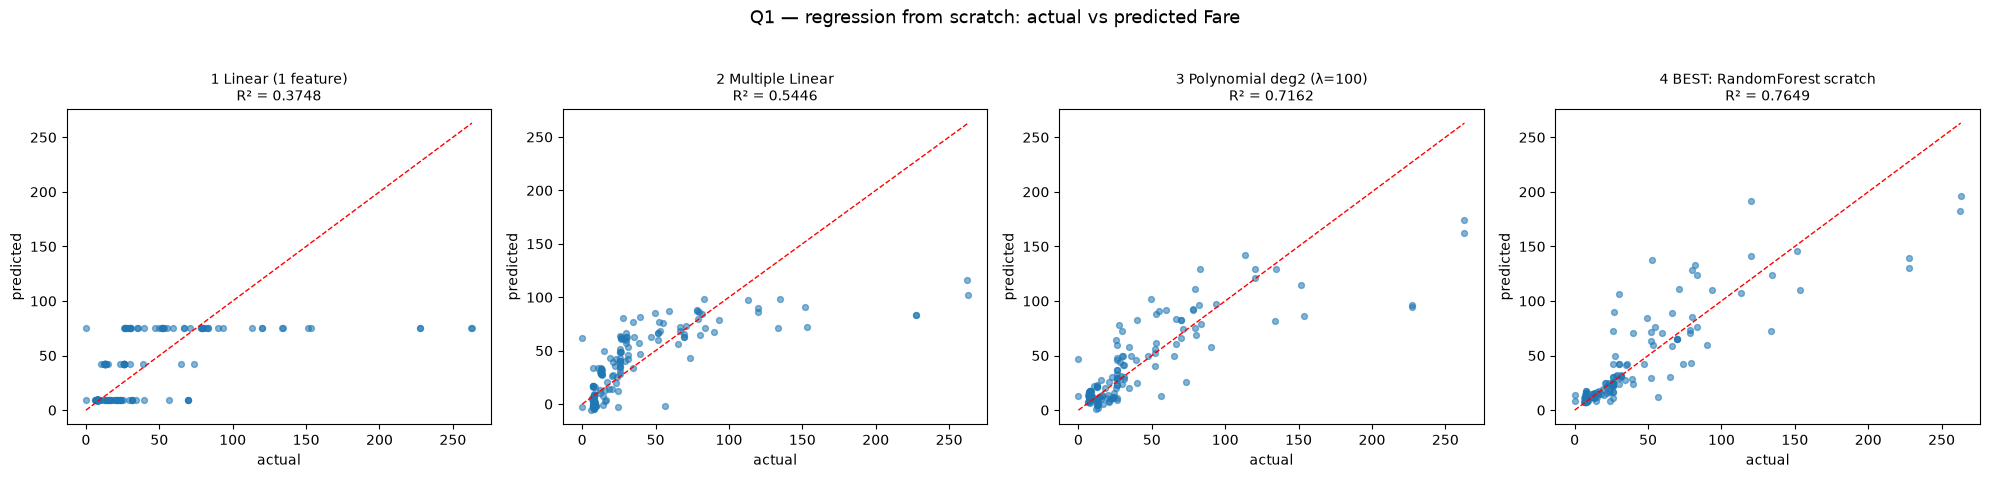

In [14]:
# ===================== Q1 PREDICT + 4 GRAPHS =====================
def pred(model_cols, Xs):
    m, cols = model_cols
    return m.predict(Xs[:, cols] if cols else Xs)

q1_pred = {name: pred(mc, X_test) for name, mc in q1_models.items()}
q1_pred_extra = {name: pred(mc, X_test) for name, mc in extra.items()}

def scatter_grid(preds, y_true, title):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
    lo, hi = min(y_true.min(), 0), y_true.max()
    for ax, (name, p) in zip(axes, preds.items()):
        ax.scatter(y_true, p, alpha=0.55, s=18)
        ax.plot([lo, hi], [lo, hi], "r--", lw=1)
        ax.set_title(f"{name}\nR² = {r2(y_true, p):.4f}", fontsize=10)
        ax.set_xlabel("actual"); ax.set_ylabel("predicted")
    fig.suptitle(title, fontsize=13, y=1.03)
    plt.tight_layout(); plt.show()

scatter_grid(q1_pred, yr_test, f"Q1 — regression from scratch: actual vs predicted {REG_TARGET}")

In [15]:
# ===================== Q1 RANKING TABLE =====================
rows = []
for name, p in {**q1_pred, **q1_pred_extra}.items():
    base = "Poly2 Ridge" if name.startswith("3 Polynomial") else name.split(": ", 1)[-1]
    rows.append({"model": name, "R2_test": r2(yr_test, p), "RMSE_test": rmse(yr_test, p),
                 "CV_R2_train": cv_scores.get(base, np.nan), "graph": name in q1_pred})
q1_table = pd.DataFrame(rows).sort_values("R2_test", ascending=False).reset_index(drop=True)
q1_table.index += 1
q1_table.index.name = "rank"
print(f"Q1 ranking (target = {REG_TARGET}); BEST picked by CV = {best_name}")
q1_table.round(4)

Q1 ranking (target = Fare); BEST picked by CV = RandomForest scratch


,model,R2_test,RMSE_test,CV_R2_train,graph
rank,,,,,
1,KNN (k=7),0.8012,19.7145,0.2429,False
2,KNN (k=15),0.7716,21.1294,0.3104,False
3,4 BEST: RandomForest scratch,0.7649,21.4359,0.4821,True
4,Blend Poly+GB+RF,0.7518,22.0291,0.4708,False
5,Blend Poly+GB(log y),0.7180,23.4806,0.4696,False
6,3 Polynomial deg2 (λ=100),0.7162,23.5548,0.4440,True
7,GradBoost scratch,0.6634,25.6509,0.3120,False
8,GradBoost scratch (log y),0.6610,25.7416,0.4284,False
9,Linear (gradient descent),0.5446,29.8363,NaN,False


In [16]:
# check: scratch multiple linear == sklearn (proves the from-scratch code is correct)
from sklearn.linear_model import LinearRegression
print("scratch R2:", round(r2(yr_test, q1_pred["2 Multiple Linear"]), 6),
      "| sklearn R2:", round(r2(yr_test, LinearRegression().fit(X_train, yr_train).predict(X_test)), 6))

scratch R2: 0.544609 | sklearn R2: 0.544609


---
# Q2 — Classification + Regression (sklearn allowed) · 15 p
1. Train many classifiers → predict → compare **accuracy + F1** (bar chart + ranking table).
2. Take the **predicted class** of the best classifier and add it as a feature → train regressors → 4 graphs + ranking table.

Leak-free trick: on TRAIN the predicted class comes from `cross_val_predict` (each row predicted by a model that never saw it); on TEST it comes from the classifier fitted on all of train. Same as your original code.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier, VotingClassifier,
                              RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor)
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import accuracy_score, f1_score, r2_score, confusion_matrix, ConfusionMatrixDisplay
try:
    from xgboost import XGBClassifier, XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
print("xgboost available:", HAS_XGB)

classes = np.unique(y_cls)
AVG = "binary" if len(classes) == 2 else "macro"
POS = classes[-1] if AVG == "binary" else None       # positive class = the larger label (1 / "yes")
f1 = lambda y, p: f1_score(y, p, average=AVG, pos_label=POS) if AVG == "binary" else f1_score(y, p, average=AVG)
lab = {c: i for i, c in enumerate(classes)}           # xgboost needs labels 0..k-1
skf = StratifiedKFold(n_splits=3 if QUICK else 5, shuffle=True, random_state=SEED)
METRIC = "f1_macro" if AVG == "macro" else "accuracy"   # what CV optimises (accuracy for 2 balanced-ish classes)
print("F1 average:", AVG, "| CV metric:", METRIC)

xgboost available: True
F1 average: binary | CV metric: accuracy


In [18]:
# ===================== Q2.1 TRAIN CLASSIFIERS =====================
classifiers = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights="distance")),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=3, probability=True, random_state=SEED)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest":       RandomForestClassifier(500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Extra Trees":         ExtraTreesClassifier(500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=SEED),          # your original (emergency)
    "HistGradBoosting":    HistGradientBoostingClassifier(random_state=SEED),
    "AdaBoost":            AdaBoostClassifier(random_state=SEED),
}
if HAS_XGB:
    classifiers["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                           colsample_bytree=0.8, random_state=SEED, verbosity=0)

# tuned Gradient Boosting (small grid, CV on train)
grid = GridSearchCV(GradientBoostingClassifier(random_state=SEED),
                    {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1], "max_depth": [2, 3, 4]},
                    cv=skf, scoring=METRIC, n_jobs=-1).fit(X_train, yc_train)
classifiers["GB tuned"] = grid.best_estimator_
print("GB tuned params:", grid.best_params_)

ytr_fit = np.array([lab[c] for c in yc_train])         # 0..k-1 labels for fitting (works for every model)
cls_cv = {}
for name, m in classifiers.items():
    cls_cv[name] = cross_val_score(m, X_train, ytr_fit, cv=skf, scoring=METRIC, n_jobs=-1).mean()
    print(f"  CV {METRIC} {cls_cv[name]:.4f}  {name}")

# soft-voting ensemble of the top 3 by CV (often the #1 model)
top3 = sorted(cls_cv, key=cls_cv.get, reverse=True)[:3]
classifiers["Voting top3"] = VotingClassifier([(n, clone(classifiers[n])) for n in top3], voting="soft")
cls_cv["Voting top3"] = cross_val_score(classifiers["Voting top3"], X_train, ytr_fit, cv=skf, scoring=METRIC, n_jobs=-1).mean()
print(f"  CV {METRIC} {cls_cv['Voting top3']:.4f}  Voting top3 = {top3}")

for m in classifiers.values():
    m.fit(X_train, ytr_fit)
best_cls_name = max(cls_cv, key=cls_cv.get)
best_cls = classifiers[best_cls_name]
print("BEST classifier by CV ->", best_cls_name)

GB tuned params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
  CV accuracy 0.7938  Logistic Regression
  CV accuracy 0.8191  KNN
  CV accuracy 0.8176  SVM (RBF)
  CV accuracy 0.8078  Decision Tree


  CV accuracy 0.8121  Random Forest


  CV accuracy 0.8163  Extra Trees
  CV accuracy 0.8120  Gradient Boosting
  CV accuracy 0.8190  HistGradBoosting


  CV accuracy 0.8078  AdaBoost


  CV accuracy 0.8036  XGBoost
  CV accuracy 0.8204  GB tuned


  CV accuracy 0.8247  Voting top3 = ['GB tuned', 'KNN', 'HistGradBoosting']


BEST classifier by CV -> Voting top3


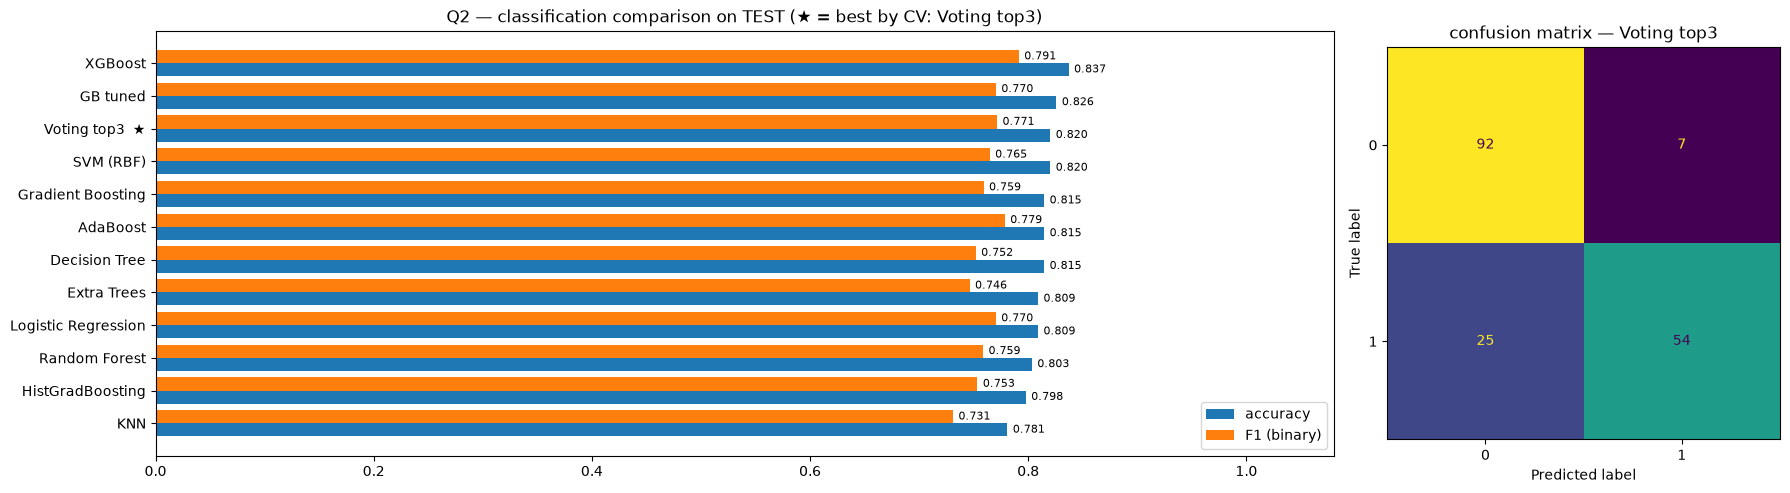

Q2 classification ranking (target = Survived)


,model,accuracy,F1,CV_accuracy
rank,,,,
1,XGBoost,0.8371,0.7914,0.8036
2,AdaBoost,0.8146,0.7785,0.8078
3,Voting top3,0.8202,0.7714,0.8247
4,GB tuned,0.8258,0.7704,0.8204
5,Logistic Regression,0.8090,0.7703,0.7938
6,SVM (RBF),0.8202,0.7647,0.8176
7,Gradient Boosting,0.8146,0.7591,0.8120
8,Random Forest,0.8034,0.7586,0.8121
9,HistGradBoosting,0.7978,0.7534,0.8190


In [19]:
# ===================== Q2.1 PREDICT + BAR CHART + RANKING =====================
cls_pred = {n: classes[m.predict(X_test).astype(int)] for n, m in classifiers.items()}
cls_table = pd.DataFrame([{"model": n, "accuracy": accuracy_score(yc_test, p), "F1": f1(yc_test, p),
                           f"CV_{METRIC}": cls_cv[n]} for n, p in cls_pred.items()])
cls_table = cls_table.sort_values(["F1", "accuracy"], ascending=False).reset_index(drop=True)
cls_table.index += 1; cls_table.index.name = "rank"

fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1]})
t = cls_table.sort_values("accuracy")
yy = np.arange(len(t))
ax[0].barh(yy - 0.2, t["accuracy"], 0.4, label="accuracy")
ax[0].barh(yy + 0.2, t["F1"], 0.4, label=f"F1 ({AVG})")
ax[0].set_yticks(yy, [f"{n}  ★" if n == best_cls_name else n for n in t["model"]])
for i, (a, f) in enumerate(zip(t["accuracy"], t["F1"])):
    ax[0].text(a + 0.005, i - 0.2, f"{a:.3f}", va="center", fontsize=8)
    ax[0].text(f + 0.005, i + 0.2, f"{f:.3f}", va="center", fontsize=8)
ax[0].set_xlim(0, 1.08); ax[0].legend(loc="lower right")
ax[0].set_title(f"Q2 — classification comparison on TEST (★ = best by CV: {best_cls_name})")
ConfusionMatrixDisplay.from_predictions(yc_test, cls_pred[best_cls_name], ax=ax[1], colorbar=False)
ax[1].set_title(f"confusion matrix — {best_cls_name}")
plt.tight_layout(); plt.show()
print(f"Q2 classification ranking (target = {CLS_TARGET or '_class'})")
cls_table.round(4)

In [20]:
# ===================== Q2.2 PREDICTED CLASS -> REGRESSION =====================
# train rows: out-of-fold prediction (no leakage); test rows: model trained on all train
oof = cross_val_predict(best_cls, X_train, ytr_fit, cv=skf, method="predict_proba", n_jobs=-1)
te_proba = best_cls.predict_proba(X_test)
Xr_train = np.c_[X_train, oof.argmax(1), oof[:, 1:]]            # + pred_class + class probabilities
Xr_test  = np.c_[X_test, te_proba.argmax(1), te_proba[:, 1:]]
reg_feature_names = feature_names + ["pred_class"] + [f"proba_{c}" for c in classes[1:]]
print("regression features:", reg_feature_names[-1 - len(classes[1:]):], "added")

kf = KFold(n_splits=3 if QUICK else 5, shuffle=True, random_state=SEED)
log_wrap = lambda m: TransformedTargetRegressor(m, func=np.log1p, inverse_func=np.expm1)
regressors = {
    "Linear Regression":     make_pipeline(StandardScaler(), LinearRegression()),
    "Polynomial deg2 Ridge": make_pipeline(StandardScaler(), PolynomialFeatures(2), Ridge(10)),
    "Gradient Boosting":     GradientBoostingRegressor(random_state=SEED),          # your original (emergency)
    "KNN":                   make_pipeline(StandardScaler(), KNeighborsRegressor(10, weights="distance")),
    "Random Forest":         RandomForestRegressor(500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Extra Trees":           ExtraTreesRegressor(500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "HistGradBoosting":      HistGradientBoostingRegressor(random_state=SEED),
}
if HAS_XGB:
    regressors["XGBoost"] = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                         colsample_bytree=0.8, random_state=SEED, verbosity=0)
if pos_y:                                   # y >= 0 and skewed (prices) -> learn log(y)
    regressors["Gradient Boosting (log y)"] = log_wrap(GradientBoostingRegressor(random_state=SEED))
    regressors["Extra Trees (log y)"] = log_wrap(ExtraTreesRegressor(500, min_samples_leaf=2, random_state=SEED, n_jobs=-1))

reg_cv = {}
for name, m in regressors.items():
    reg_cv[name] = cross_val_score(m, Xr_train, yr_train, cv=kf, scoring="r2", n_jobs=-1).mean()
    print(f"  CV R2 {reg_cv[name]:7.4f}  {name}")

top3r = sorted(reg_cv, key=reg_cv.get, reverse=True)[:3]
regressors["Stacking top3"] = StackingRegressor([(n.replace(" ", "_"), clone(regressors[n])) for n in top3r],
                                                final_estimator=Ridge(1.0), cv=kf, n_jobs=-1)
reg_cv["Stacking top3"] = cross_val_score(regressors["Stacking top3"], Xr_train, yr_train, cv=kf, scoring="r2", n_jobs=-1).mean()
print(f"  CV R2 {reg_cv['Stacking top3']:7.4f}  Stacking top3 = {top3r}")

for m in regressors.values():
    m.fit(Xr_train, yr_train)
best_reg_name = max(reg_cv, key=reg_cv.get)
print("BEST regressor by CV ->", best_reg_name)

regression features: ['pred_class', 'proba_1'] added
  CV R2  0.3144  Linear Regression
  CV R2  0.3858  Polynomial deg2 Ridge
  CV R2  0.1378  Gradient Boosting
  CV R2  0.1518  KNN


  CV R2  0.2754  Random Forest


  CV R2  0.2090  Extra Trees
  CV R2  0.2551  HistGradBoosting


  CV R2  0.0009  XGBoost
  CV R2  0.3797  Gradient Boosting (log y)


  CV R2  0.3630  Extra Trees (log y)


  CV R2  0.4101  Stacking top3 = ['Polynomial deg2 Ridge', 'Gradient Boosting (log y)', 'Extra Trees (log y)']


BEST regressor by CV -> Stacking top3


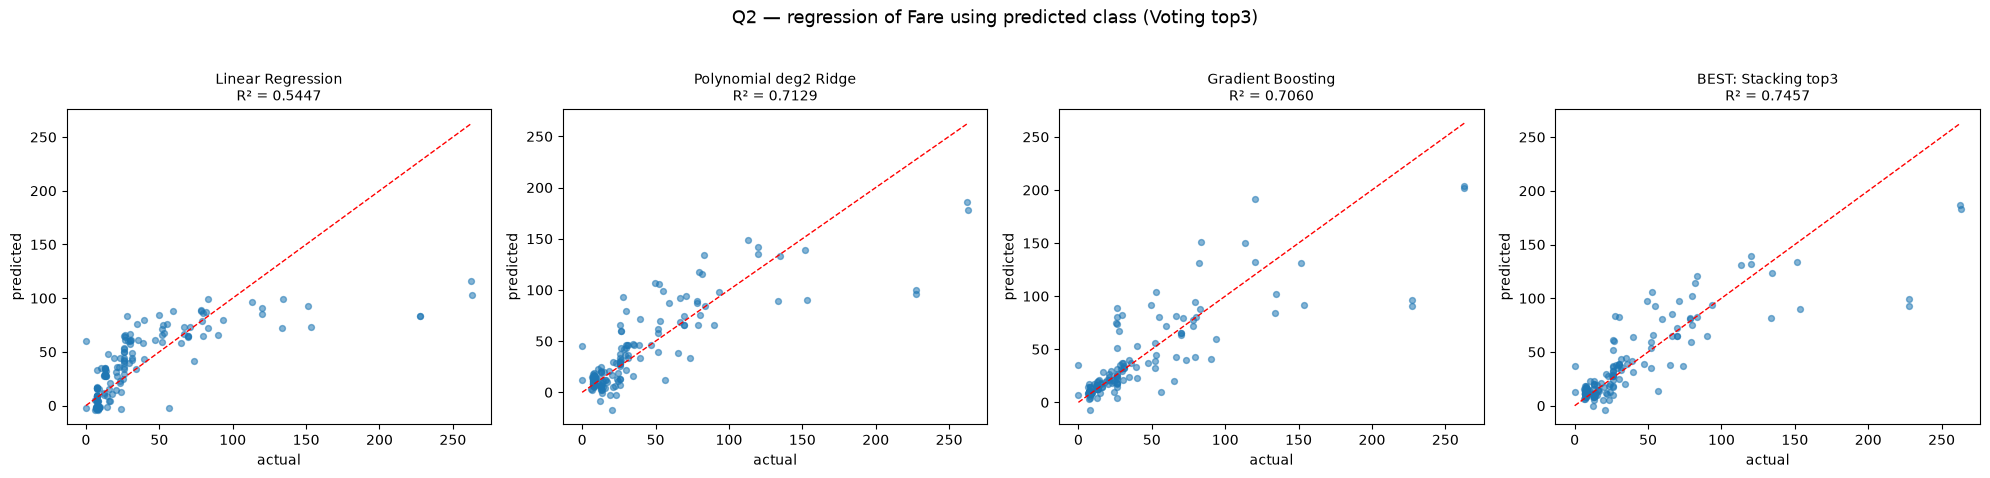

Q2 regression ranking (target = Fare, features + predicted class)


,model,R2_test,RMSE_test,CV_R2_train
rank,,,,
1,Extra Trees (log y),0.7709,21.1619,0.3630
2,Extra Trees,0.7486,22.1696,0.2090
3,Stacking top3,0.7457,22.2972,0.4101
4,KNN,0.7337,22.8154,0.1518
5,Gradient Boosting (log y),0.7222,23.3021,0.3797
6,Polynomial deg2 Ridge,0.7129,23.6905,0.3858
7,Gradient Boosting,0.7060,23.9729,0.1378
8,XGBoost,0.6942,24.4500,0.0009
9,Random Forest,0.6861,24.7702,0.2754


In [21]:
# ===================== Q2.2 4 GRAPHS + RANKING =====================
reg_pred = {n: m.predict(Xr_test) for n, m in regressors.items()}
four = {"Linear Regression": reg_pred["Linear Regression"],
        "Polynomial deg2 Ridge": reg_pred["Polynomial deg2 Ridge"],
        "Gradient Boosting": reg_pred["Gradient Boosting"],
        f"BEST: {best_reg_name}": reg_pred[best_reg_name]}
scatter_grid(four, yr_test, f"Q2 — regression of {REG_TARGET} using predicted class ({best_cls_name})")

reg_table = pd.DataFrame([{"model": n, "R2_test": r2_score(yr_test, p), "RMSE_test": rmse(yr_test, p),
                           "CV_R2_train": reg_cv[n]} for n, p in reg_pred.items()])
reg_table = reg_table.sort_values("R2_test", ascending=False).reset_index(drop=True)
reg_table.index += 1; reg_table.index.name = "rank"
print(f"Q2 regression ranking (target = {REG_TARGET}, features + predicted class)")
reg_table.round(4)

In [22]:
# does the predicted class actually help?  same best model with vs without it
m_wo = clone(regressors[best_reg_name]).fit(X_train, yr_train)
print(f"{best_reg_name}: R2 without pred_class = {r2_score(yr_test, m_wo.predict(X_test)):.4f}"
      f" | with pred_class = {r2_score(yr_test, reg_pred[best_reg_name]):.4f}")

Stacking top3: R2 without pred_class = 0.7684 | with pred_class = 0.7457


---
# Predict a row the teacher gives (ถ้าอาจารย์ให้ค่ามาทาย)
Write the raw values like the csv (text stays text). Missing columns get the training median / 0.

In [23]:
given = {"Pclass": 1, "Sex": "female", "Age": 30, "SibSp": 0, "Parch": 0, "Embarked": "C"}   # <<< CHANGE

def make_row(values):
    r = pd.DataFrame([values])
    r = pd.get_dummies(r, dtype=float)
    r = r.reindex(columns=feature_names)
    med = pd.Series(X_train.mean(0) if FILL == "mean" else np.median(X_train, 0), index=feature_names)
    for c in feature_names:                                   # not given -> training median (dummy columns -> 0)
        if pd.isna(r.loc[0, c]):
            r.loc[0, c] = 0.0 if any(c.startswith(k + "_") for k in values) else med[c]
    return r.to_numpy(float)

xg = make_row(given)
print("Q1", REG_TARGET, "->", {n: round(float(pred(mc, xg)[0]), 3) for n, mc in q1_models.items()})
pc = best_cls.predict_proba(xg)
print("Q2 class ->", classes[pc.argmax(1)][0], "| proba", pc.round(3)[0], f"({best_cls_name})")
xr = np.c_[xg, pc.argmax(1), pc[:, 1:]]
print("Q2", REG_TARGET, "->", round(float(regressors[best_reg_name].predict(xr)[0]), 3), f"({best_reg_name})")

Q1 Fare -> {'1 Linear (1 feature)': 75.228, '2 Multiple Linear': 84.521, '3 Polynomial deg2 (λ=100)': 99.586, '4 BEST: RandomForest scratch': 78.176}
Q2 class -> 1 | proba [0.017 0.983] (Voting top3)
Q2 Fare -> 94.73 (Stacking top3)


---
# EMERGENCY (time almost over / something broke)
Your original short versions. Change the csv / columns at the top and run only these two cells.

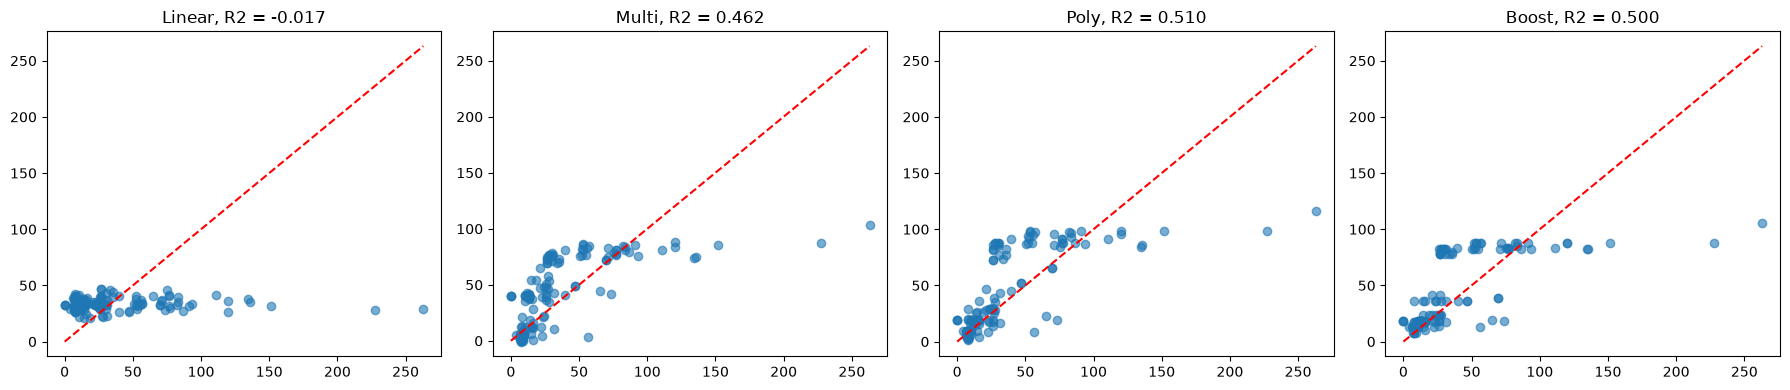

 model        R2
  Poly  0.510050
 Boost  0.500198
 Multi  0.461845
Linear -0.016816


In [24]:
# EMERGENCY Q1 — from scratch, 4 graphs (Linear, Multi, Poly, Boost) + ranking
df_e = pd.read_csv("../titanic.csv")                        # <<< CHANGE
cols_e, target_e = ["Age", "Pclass", "SibSp"], "Fare"     # <<< CHANGE
df_e = df_e[cols_e + [target_e]]
df_e = df_e.fillna(df_e.median(numeric_only=True)).sample(frac=1, random_state=42)
xe, ye = df_e[cols_e].values.astype(float), df_e[target_e].values
n = int(len(df_e) * 0.8)
xe_tr, xe_te, ye_tr, ye_te = xe[:n], xe[n:], ye[:n], ye[n:]

def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w

def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                a, b = error[left].mean(), error[~left].mean()
                fix_train = np.where(left, a, b)
                loss = ((error - fix_train) ** 2).sum()
                if loss < best:
                    best, best_train, best_test = loss, fix_train, np.where(X_test[:, j] <= t, a, b)
        pred_train += 0.1 * best_train
        pred_test += 0.1 * best_test
    return pred_test

pe = {"Linear": linear(xe_tr[:, :1], ye_tr, xe_te[:, :1]),
      "Multi": linear(xe_tr, ye_tr, xe_te),
      "Poly": linear(np.column_stack([xe_tr, xe_tr ** 2]), ye_tr, np.column_stack([xe_te, xe_te ** 2])),
      "Boost": boost(xe_tr, ye_tr, xe_te)}
plt.figure(figsize=(18, 4))
for i, (name, p) in enumerate(pe.items(), 1):
    plt.subplot(1, 4, i)
    plt.scatter(ye_te, p, alpha=0.6); plt.plot([0, ye_te.max()], [0, ye_te.max()], "r--")
    plt.title(f"{name}, R2 = {r2(ye_te, p):.3f}")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"model": list(pe), "R2": [r2(ye_te, p) for p in pe.values()]}).sort_values("R2", ascending=False).to_string(index=False))

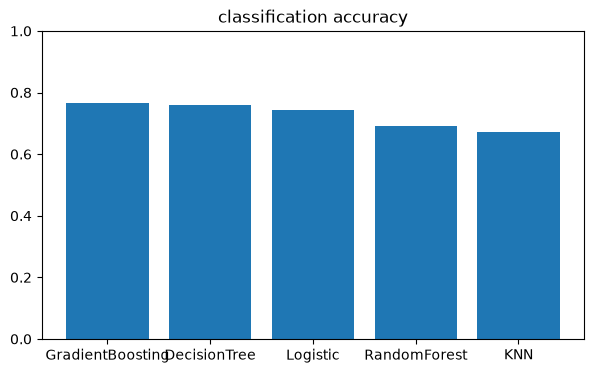

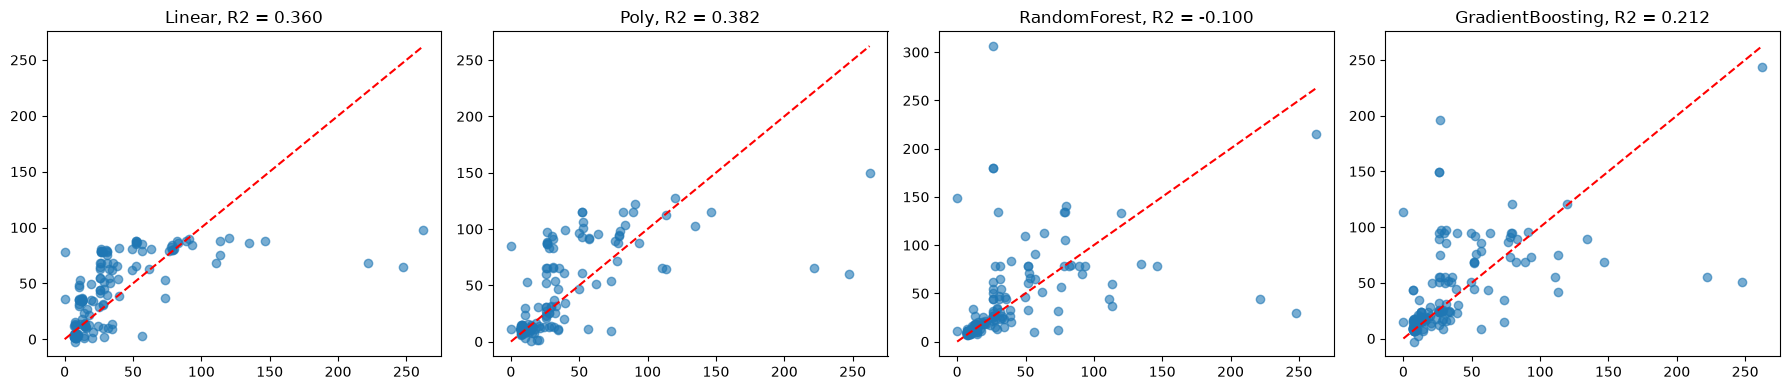

           model  accuracy       F1
GradientBoosting  0.765363 0.742816
    DecisionTree  0.759777 0.737635
        Logistic  0.743017 0.716226
    RandomForest  0.692737 0.661974
             KNN  0.670391 0.644853

           model        R2
            Poly  0.381857
          Linear  0.359849
GradientBoosting  0.211969
    RandomForest -0.100164


In [25]:
# EMERGENCY Q2 — your Gradient Boosting version + bar chart + 4 regression graphs + 2 ranking tables
from sklearn.model_selection import train_test_split
df_e = pd.read_csv("../titanic.csv")                        # <<< CHANGE
cols_e, cls_e, reg_e = ["Age", "Pclass", "SibSp"], "Survived", "Fare"   # <<< CHANGE
df_e = df_e[cols_e + [cls_e, reg_e]]
df_e = df_e.fillna(df_e.median(numeric_only=True))
xtr, xte, ytr, yte = train_test_split(df_e[cols_e], df_e[[cls_e, reg_e]], test_size=0.2, random_state=42)

clfs = {"Logistic": LogisticRegression(max_iter=1000), "KNN": KNeighborsClassifier(),
        "DecisionTree": DecisionTreeClassifier(max_depth=4), "RandomForest": RandomForestClassifier(300, random_state=42),
        "GradientBoosting": GradientBoostingClassifier(random_state=42)}
ct = []
for name, m in clfs.items():
    p = m.fit(xtr, ytr[cls_e]).predict(xte)
    ct.append((name, accuracy_score(yte[cls_e], p), f1_score(yte[cls_e], p, average="macro")))
ct = pd.DataFrame(ct, columns=["model", "accuracy", "F1"]).sort_values("accuracy", ascending=False)
best_e = clfs[ct.iloc[0]["model"]]

xtr, xte = xtr.copy(), xte.copy()
xtr["pred_class"] = cross_val_predict(best_e, xtr[cols_e], ytr[cls_e], cv=5)
xte["pred_class"] = best_e.predict(xte[cols_e])
regs = {"Linear": LinearRegression(), "Poly": make_pipeline(PolynomialFeatures(2), LinearRegression()),
        "RandomForest": RandomForestRegressor(300, random_state=42), "GradientBoosting": GradientBoostingRegressor(random_state=42)}
rp = {n: m.fit(xtr, ytr[reg_e]).predict(xte) for n, m in regs.items()}

plt.figure(figsize=(7, 4)); plt.bar(ct["model"], ct["accuracy"]); plt.ylim(0, 1); plt.title("classification accuracy"); plt.show()
plt.figure(figsize=(18, 4))
for i, (n, p) in enumerate(rp.items(), 1):
    plt.subplot(1, 4, i); plt.scatter(yte[reg_e], p, alpha=0.6)
    plt.plot([0, yte[reg_e].max()], [0, yte[reg_e].max()], "r--"); plt.title(f"{n}, R2 = {r2_score(yte[reg_e], p):.3f}")
plt.tight_layout(); plt.show()
print(ct.to_string(index=False)); print()
print(pd.DataFrame({"model": list(rp), "R2": [r2_score(yte[reg_e], p) for p in rp.values()]}).sort_values("R2", ascending=False).to_string(index=False))

---
# Checklist before you submit
1. **Restart & Run All** once, with no errors. Every ranking table is visible.
2. Same `SEED = 42` everywhere, and nothing is tuned on TEST (CV on train only).
3. Q1 uses **numpy only** for the models. sklearn appears only in the "check" cell, which is optional, so delete it if the teacher is strict.
4. Scratch Multiple Linear R² == sklearn R² → proves your OLS is right.
5. Write 1–2 lines under each table. For example:
   - "**X** ranks first (R² = …). Trees/boosting catch non-linear patterns and feature interactions that a straight line can't. Linear (1 feature) is worst because one column can't explain the target."
   - "F1 matters more than accuracy when the classes are imbalanced."
   - "Adding the predicted class changed R² from … to …"
6. Ranking vs friends: report the **BEST** row. If a friend asks about your trick, it's 5-fold CV model selection plus a log-target/ensemble.